# Polynomial Regression
---

## Experiment: fit a quadratic polynomial from its design matrix.

Quadratic coefficients [intercept, x, x^2]: [ 1.3939 -0.754   1.2225]
Design rank: 3
scikit-learn coefficients: [ 1.3939 -0.754   1.2225]
Coefficient differences: [ 0.  0. -0.]


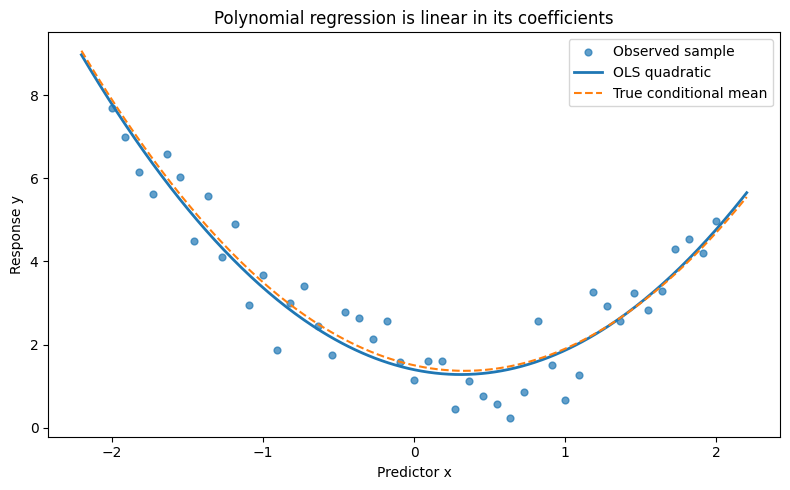

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(124)
x = np.linspace(-2, 2, 45)
y = 1.5 - 0.8*x + 1.2*x**2 + rng.normal(0, 0.7, x.size)

# Vandermonde matrix: columns 1, x, x^2.
X = np.column_stack((np.ones_like(x), x, x**2))
coef, residual_sums, rank, singular_values = np.linalg.lstsq(
    X, y, rcond=None)
print("Quadratic coefficients [intercept, x, x^2]:", np.round(coef, 4))
print("Design rank:", rank)

# The same model using a feature transformer and an OLS estimator.
features = PolynomialFeatures(degree=2, include_bias=False)
XP = features.fit_transform(x.reshape(-1, 1))
model = LinearRegression().fit(XP, y)
print("scikit-learn coefficients:",
      np.round(np.r_[model.intercept_, model.coef_], 4))
print("Coefficient differences:",
      np.round(np.r_[model.intercept_, model.coef_] - coef, 10))

grid = np.linspace(-2.2, 2.2, 300)
grid_X = np.column_stack((np.ones_like(grid), grid, grid**2))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=24, alpha=0.7, label="Observed sample")
ax.plot(grid, grid_X @ coef, linewidth=2, label="OLS quadratic")
ax.plot(grid, 1.5 - 0.8*grid + 1.2*grid**2,
        linestyle="--", label="True conditional mean")
ax.set(xlabel="Predictor x", ylabel="Response y",
       title="Polynomial regression is linear in its coefficients")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_quadratic_fit.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: compare underfitting, useful complexity, and overfitting.

Degree  1: train RMSE=0.614, independent test RMSE=0.687
Degree  3: train RMSE=0.258, independent test RMSE=0.291
Degree 16: train RMSE=0.210, independent test RMSE=1574.612


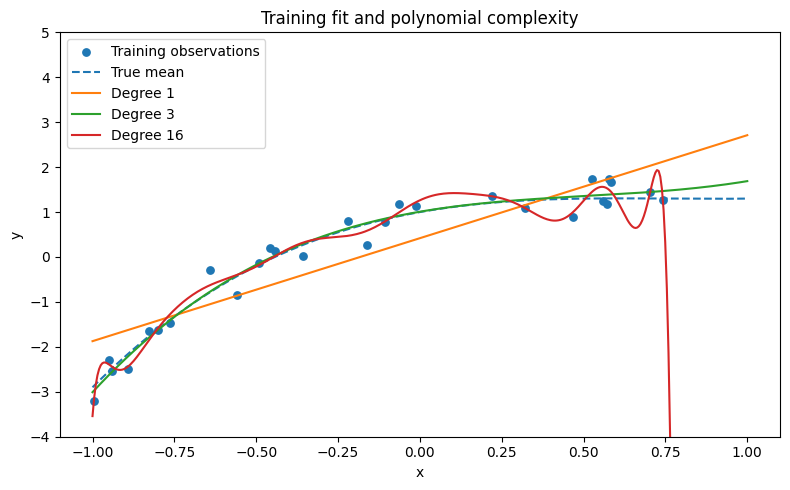

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(125)
def mean_curve(x):
    return 1 + 1.3*x - 1.8*x**2 + 0.8*x**3

x_train = np.sort(rng.uniform(-1, 1, 28))
y_train = mean_curve(x_train) + rng.normal(0, 0.28, x_train.size)
x_test = rng.uniform(-1, 1, 1000)
y_test = mean_curve(x_test) + rng.normal(0, 0.28, x_test.size)
grid = np.linspace(-1, 1, 400)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_train, y_train, s=28, label="Training observations")
ax.plot(grid, mean_curve(grid), linestyle="--", label="True mean")
for degree in (1, 3, 16):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          LinearRegression())
    model.fit(x_train[:, None], y_train)
    train_rmse = np.sqrt(mean_squared_error(
        y_train, model.predict(x_train[:, None])))
    test_rmse = np.sqrt(mean_squared_error(
        y_test, model.predict(x_test[:, None])))
    print(f"Degree {degree:2d}: train RMSE={train_rmse:.3f}, "
          f"independent test RMSE={test_rmse:.3f}")
    ax.plot(grid, model.predict(grid[:, None]),
            label=f"Degree {degree}")
ax.set(xlabel="x", ylabel="y", ylim=(-4, 5),
       title="Training fit and polynomial complexity")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_degree_overfit.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: construct a multivariable polynomial feature matrix with an interaction.

In [3]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score

rng = np.random.default_rng(126)
X = rng.uniform(-1, 1, size=(180, 2))
y = 2 + X[:, 0] - 0.7*X[:, 1] + 3*X[:, 0]*X[:, 1]
y = y + rng.normal(0, 0.25, len(y))

poly = PolynomialFeatures(degree=2, include_bias=False)
XP = poly.fit_transform(X)
print("Feature names:", poly.get_feature_names_out(["x1", "x2"]))
print("Feature-matrix shape:", XP.shape)

cv = KFold(n_splits=5, shuffle=True, random_state=126)
for title, estimator in [
    ("Main effects only", LinearRegression()),
    ("Quadratic with interactions",
     make_pipeline(PolynomialFeatures(2, include_bias=False),
                   LinearRegression()))
]:
    scores = cross_val_score(estimator, X, y, cv=cv,
                             scoring="neg_mean_squared_error")
    print(f"{title}: cross-validated RMSE="
          f"{np.sqrt(-scores).mean():.3f}")

Feature names: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
Feature-matrix shape: (180, 5)
Main effects only: cross-validated RMSE=1.104
Quadratic with interactions: cross-validated RMSE=0.251


## Experiment: select polynomial degree by cross-validation and evaluate a held-out test set.

Selected polynomial degree: 2
CV RMSE (used for selection): 0.487
Independent test RMSE (reported once): 0.550


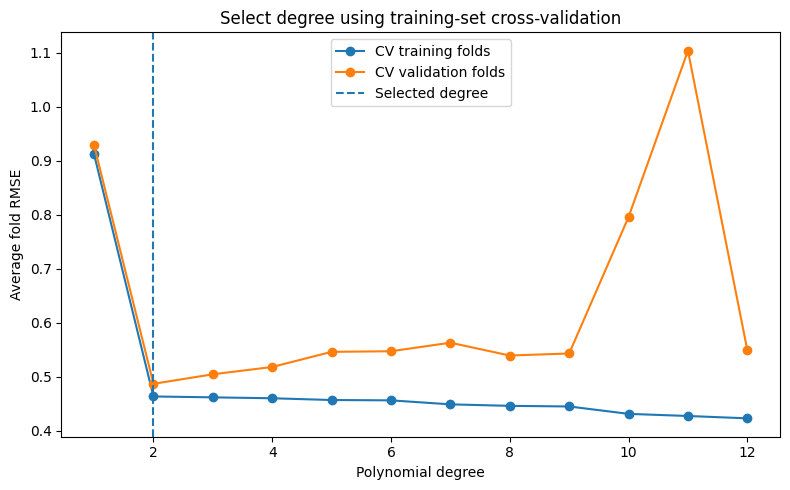

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(127)
x = rng.uniform(-1.5, 1.5, 130)
y = 1 + 0.5*x - 1.3*x**2 + rng.normal(0, 0.5, len(x))
X_train, X_test, y_train, y_test = train_test_split(
    x[:, None], y, test_size=0.25, random_state=127)
cv = KFold(n_splits=5, shuffle=True, random_state=127)

degrees = range(1, 13)
train_rmse, validation_rmse = [], []
for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          LinearRegression())
    result = cross_validate(model, X_train, y_train, cv=cv,
                            scoring="neg_mean_squared_error",
                            return_train_score=True)
    train_rmse.append(np.sqrt(-result["train_score"]).mean())
    validation_rmse.append(np.sqrt(-result["test_score"]).mean())

best_degree = degrees[int(np.argmin(validation_rmse))]
final_model = make_pipeline(
    PolynomialFeatures(best_degree, include_bias=False),
    LinearRegression()).fit(X_train, y_train)
held_out_rmse = np.sqrt(mean_squared_error(
    y_test, final_model.predict(X_test)))
print("Selected polynomial degree:", best_degree)
print(f"CV RMSE (used for selection): {min(validation_rmse):.3f}")
print(f"Independent test RMSE (reported once): {held_out_rmse:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(list(degrees), train_rmse, marker="o", label="CV training folds")
ax.plot(list(degrees), validation_rmse, marker="o", label="CV validation folds")
ax.axvline(best_degree, linestyle="--", label="Selected degree")
ax.set(xlabel="Polynomial degree", ylabel="Average fold RMSE",
       title="Select degree using training-set cross-validation")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_cv_degree.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: control a high-degree polynomial using Ridge regularization.

High-degree OLS: independent test RMSE=1.058
High-degree Ridge: independent test RMSE=0.248


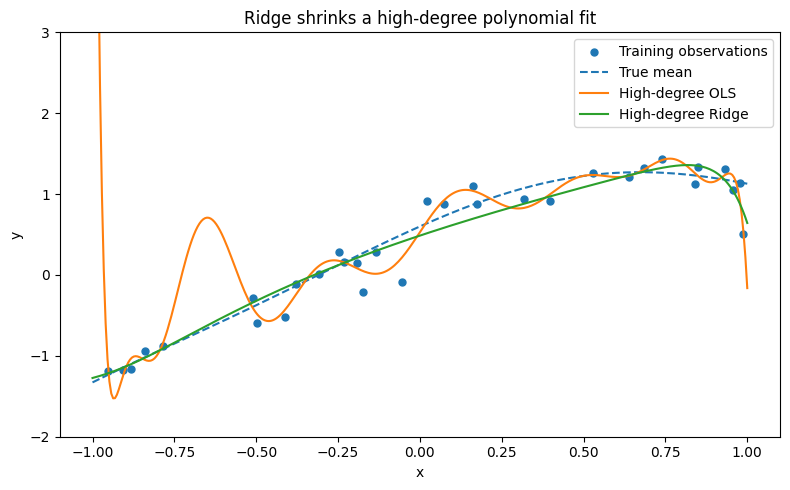

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(128)
def true_mean(x):
    return 0.6 + 1.2*x - 0.7*x**2 + 0.2*np.sin(3*x)

x_train = np.sort(rng.uniform(-1, 1, 32))
y_train = true_mean(x_train) + rng.normal(0, 0.23, len(x_train))
x_test = rng.uniform(-1, 1, 1000)
y_test = true_mean(x_test) + rng.normal(0, 0.23, len(x_test))
grid = np.linspace(-1, 1, 350)

models = {
    "High-degree OLS": make_pipeline(
        PolynomialFeatures(16, include_bias=False),
        StandardScaler(), LinearRegression()),
    "High-degree Ridge": make_pipeline(
        PolynomialFeatures(16, include_bias=False),
        StandardScaler(), Ridge(alpha=1.0))
}
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_train, y_train, s=25, label="Training observations")
ax.plot(grid, true_mean(grid), linestyle="--", label="True mean")
for label, model in models.items():
    model.fit(x_train[:, None], y_train)
    rmse = np.sqrt(mean_squared_error(
        y_test, model.predict(x_test[:, None])))
    print(f"{label}: independent test RMSE={rmse:.3f}")
    ax.plot(grid, model.predict(grid[:, None]), label=label)
ax.set(xlabel="x", ylabel="y", ylim=(-2, 3),
       title="Ridge shrinks a high-degree polynomial fit")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_ridge_regularization.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: compare raw and centered polynomial design matrices.

In [6]:
import numpy as np

rng = np.random.default_rng(129)
x = np.linspace(95, 105, 60)
z = (x - 100) / 5  # centered, dimensionless feature
true_y = 4 + 0.6*z - 1.2*z**2 + 0.3*z**3
y = true_y + rng.normal(0, 0.12, len(x))

# Both designs span the same polynomial functions in exact arithmetic.
X_raw = np.vander(x, N=7, increasing=True)
X_scaled = np.vander(z, N=7, increasing=True)
for name, design in [("Raw x", X_raw), ("Centered/scaled x", X_scaled)]:
    cond = np.linalg.cond(design)
    coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
    fitted = design @ coefficients
    print(f"{name:18s}: condition number={cond:.3e}, "
          f"SSE={np.sum((y - fitted)**2):.4f}, "
          f"numerical rank={np.linalg.matrix_rank(design)}")
print("A coordinate change preserves the polynomial space in exact arithmetic,")
print("but a poorly scaled numerical design can lose effective rank.")

Raw x             : condition number=3.132e+21, SSE=0.7653, numerical rank=4
Centered/scaled x : condition number=9.583e+01, SSE=0.7041, numerical rank=7
A coordinate change preserves the polynomial space in exact arithmetic,
but a poorly scaled numerical design can lose effective rank.


## Experiment: test a prespecified quadratic term against a straight-line model.

Reduced SSE=220.773; full SSE=73.913
Quadratic-term F=172.8618; p-value=2.2122e-22
statsmodels comparison (F, p, df difference): (172.8617984151401, 2.2121907602800734e-22, 1.0)
Quadratic coefficient 95% CI: [0.8894 1.2062]


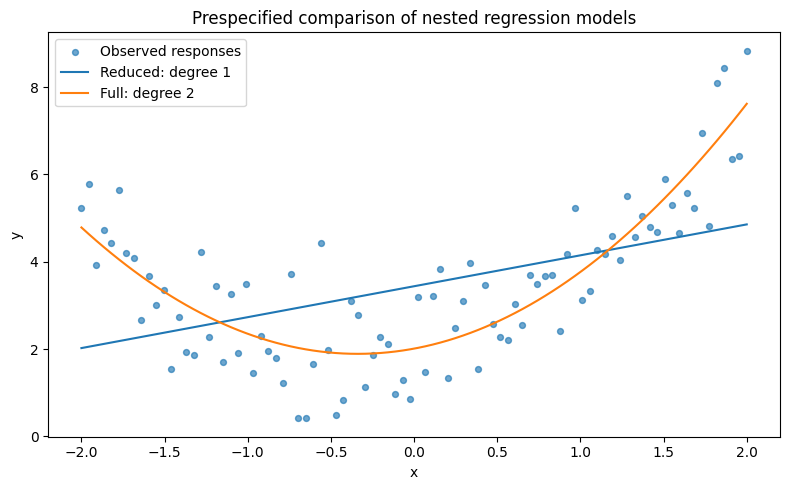

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

rng = np.random.default_rng(130)
x = np.linspace(-2, 2, 90)
y = 2 + 0.7*x + 1.1*x**2 + rng.normal(0, 1.0, len(x))

reduced = sm.OLS(y, sm.add_constant(x)).fit()
full = sm.OLS(y, np.column_stack((np.ones(len(x)), x, x**2))).fit()
sse_r = np.sum(reduced.resid**2)
sse_f = np.sum(full.resid**2)
F = ((sse_r - sse_f)/1) / (sse_f/(len(x) - 3))
p_value = stats.f.sf(F, 1, len(x) - 3)
print(f"Reduced SSE={sse_r:.3f}; full SSE={sse_f:.3f}")
print(f"Quadratic-term F={F:.4f}; p-value={p_value:.5g}")
print("statsmodels comparison (F, p, df difference):",
      full.compare_f_test(reduced))
print("Quadratic coefficient 95% CI:",
      np.round(full.conf_int()[2], 4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=18, alpha=0.65, label="Observed responses")
ax.plot(x, reduced.fittedvalues, label="Reduced: degree 1")
ax.plot(x, full.fittedvalues, label="Full: degree 2")
ax.set(xlabel="x", ylabel="y",
       title="Prespecified comparison of nested regression models")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_nested_f_test.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: visualize uncertainty in extrapolation beyond the observed range.

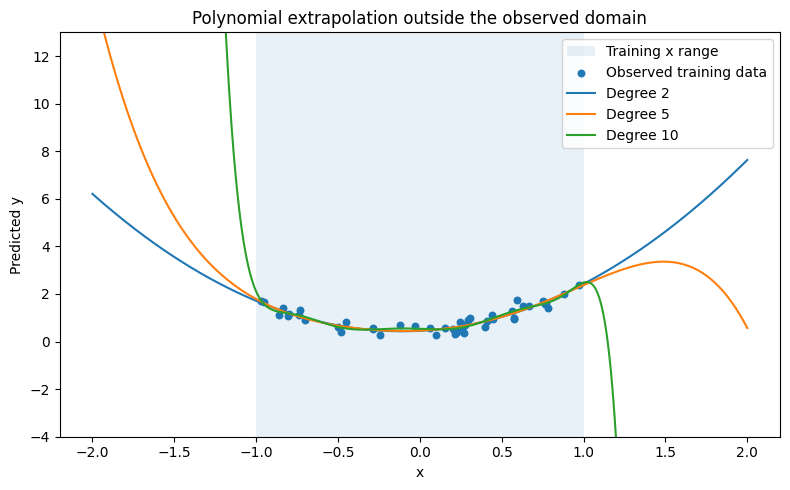

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

rng = np.random.default_rng(131)
x = np.sort(rng.uniform(-1, 1, 45))
y = 0.5 + 0.4*x + 1.6*x**2 + rng.normal(0, 0.22, len(x))
grid = np.linspace(-2, 2, 500)

fig, ax = plt.subplots(figsize=(8, 5))
ax.axvspan(-1, 1, alpha=0.10, label="Training x range")
ax.scatter(x, y, s=22, label="Observed training data")
for degree in (2, 5, 10):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          LinearRegression()).fit(x[:, None], y)
    pred = model.predict(grid[:, None])
    ax.plot(grid, pred, label=f"Degree {degree}")
ax.set(xlabel="x", ylabel="Predicted y", ylim=(-4, 13),
       title="Polynomial extrapolation outside the observed domain")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_extrapolation.png", dpi=170, bbox_inches="tight")
plt.show()

## Experiment: compare polynomial models on the SOGA-Py student dataset.

Data source: SOGA-Py students (external dataset) | complete observations: 8239
Degree 1: 5-fold CV RMSE=2.951
Degree 2: 5-fold CV RMSE=2.480
Degree 3: 5-fold CV RMSE=2.473
Selected degree: 3; held-out RMSE: 2.457


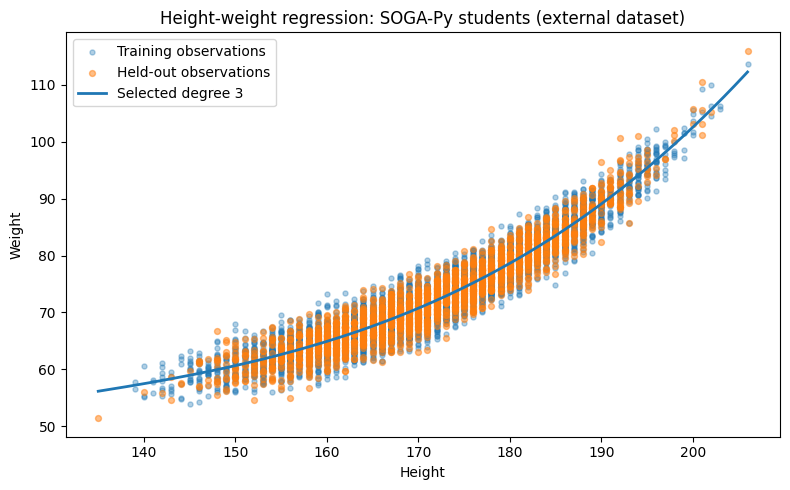

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
try:
    students = pd.read_csv(url)
    data_source = "SOGA-Py students (external dataset)"
except Exception as error:
    print("External data unavailable; using a simulated example instead:",
          type(error).__name__)
    rng = np.random.default_rng(132)
    height = rng.normal(171, 9, 450)
    weight = 68 + 0.60*(height - 171) + 0.012*(height - 171)**2
    weight += rng.normal(0, 7.5, height.size)
    students = pd.DataFrame({"height": height, "weight": weight})
    data_source = "SIMULATED DEMONSTRATION DATA"

clean = students[["height", "weight"]].apply(
    pd.to_numeric, errors="coerce").dropna()
if len(clean) < 25:
    raise ValueError("Need at least 25 complete height/weight observations")
X = clean[["height"]].to_numpy()
y = clean["weight"].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=132)
cv = KFold(n_splits=5, shuffle=True, random_state=132)

models = {}
for degree in (1, 2, 3):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                          LinearRegression())
    fold_rmse = np.sqrt(-cross_val_score(
        model, X_train, y_train, cv=cv,
        scoring="neg_mean_squared_error"))
    models[degree] = (fold_rmse.mean(), model)

selected_degree = min(models, key=lambda d: models[d][0])
selected_model = models[selected_degree][1].fit(X_train, y_train)
test_rmse = np.sqrt(mean_squared_error(
    y_test, selected_model.predict(X_test)))
print("Data source:", data_source, "| complete observations:", len(clean))
for degree, (cv_rmse, _) in models.items():
    print(f"Degree {degree}: 5-fold CV RMSE={cv_rmse:.3f}")
print(f"Selected degree: {selected_degree}; held-out RMSE: {test_rmse:.3f}")

height_grid = np.linspace(X.min(), X.max(), 250).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_train[:, 0], y_train, s=13, alpha=0.35,
           label="Training observations")
ax.scatter(X_test[:, 0], y_test, s=18, alpha=0.50,
           label="Held-out observations")
ax.plot(height_grid[:, 0], selected_model.predict(height_grid),
        linewidth=2, label=f"Selected degree {selected_degree}")
ax.set(xlabel="Height", ylabel="Weight",
       title=f"Height-weight regression: {data_source}")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/poly_students_height_weight.png", dpi=170,
            bbox_inches="tight")
plt.show()